In [ ]:
# Data processing
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Modeling and Evaluation
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from prophet import Prophet

pd.set_option("display.float_format", "{:.3f}".format)

# Read Data

Data penjualan red wine/anggur merah bulanan dari 1980 hingga 1995

In [ ]:
red_wine = pd.read_csv('Red_Wine.csv')

red_wine.rename(columns= {'RED WINE': 'demand'}, inplace = True)

# Convert YEAR + MONTH into a proper monthly date
red_wine["DATE"] = pd.to_datetime(
    red_wine["YEAR"].astype(str) + "-" + red_wine["MONTH"],
    format="%Y-%B"
)

# Keep only the useful columns
red_wine = red_wine[["DATE", "demand"]]

# Sort chronologically
red_wine = red_wine.sort_values("DATE").reset_index(drop=True)

# Set DATE as index
red_wine = red_wine.set_index("DATE")
red_wine = red_wine.asfreq("MS")

red_wine.tail(12)

,demand
DATE,
1994-08-01,2665
1994-09-01,2639
1994-10-01,2226
1994-11-01,2586
1994-12-01,2684
1995-01-01,1185
1995-02-01,1749
1995-03-01,2459
1995-04-01,2618


# Monthly Demand

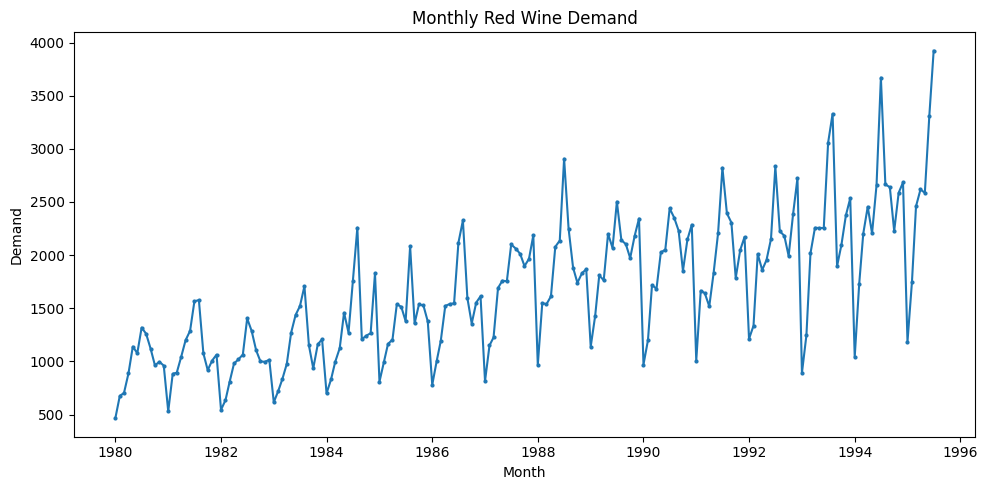

In [ ]:
import matplotlib.pyplot as plt

# Make sure the index is datetime
red_wine.index = pd.to_datetime(red_wine.index)

plt.figure(figsize=(10, 5))

plt.plot(
    red_wine.index,
    red_wine['demand'],
    marker='o',
    markersize=2
)

plt.title('Monthly Red Wine Demand')
plt.xlabel('Month')
plt.ylabel('Demand')

plt.tight_layout()

plt.show()

# Time Series Model

## Moving Average

In [ ]:
ma_red_wine = red_wine.copy()

ma_red_wine["MA_3"] = red_wine["demand"].rolling(window=3).mean().shift(1)

ma_red_wine["MA_6"] = red_wine["demand"].rolling(window=6).mean().shift(1)

ma_red_wine.tail(12)

,demand,MA_3,MA_6
DATE,,,
1994-08-01,2665,2844.667,2486.333
1994-09-01,2639,2998.333,2642.500
1994-10-01,2226,2991.333,2715.500
1994-11-01,2586,2510.000,2677.333
1994-12-01,2684,2483.667,2741.000
1995-01-01,1185,2498.667,2745.000
1995-02-01,1749,2151.667,2330.833
1995-03-01,2459,1872.667,2178.167
1995-04-01,2618,1797.667,2148.167


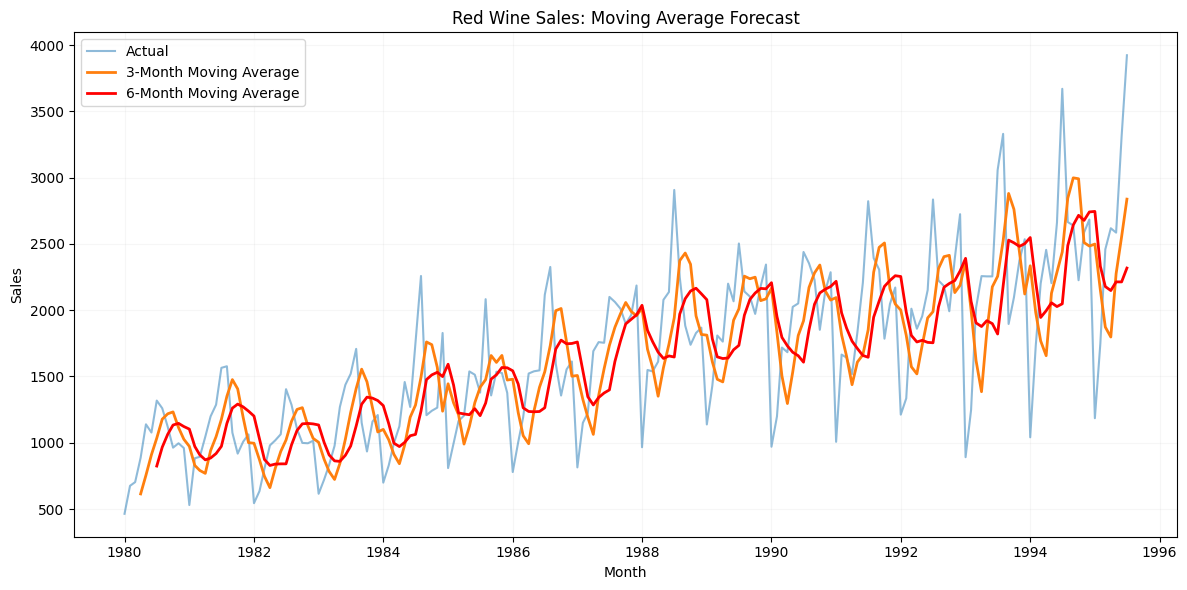

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    ma_red_wine.index,
    ma_red_wine["demand"],
    label="Actual",
    alpha = 0.5
)

plt.plot(
    ma_red_wine.index,
    ma_red_wine["MA_3"],
    label="3-Month Moving Average",
    linewidth = 2
)

plt.plot(
    ma_red_wine.index,
    ma_red_wine["MA_6"],
    label="6-Month Moving Average",
    linewidth = 2,
    color = "red"
)

plt.title("Red Wine Sales: Moving Average Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.legend()
plt.grid(True, alpha=0.1)
plt.tight_layout()
plt.show()

**Summary**

- Moving average hanya melihat sekian periode terakhir
- Forecast jangka panjang lama-lama akan membentuk garis lurus
- Akan selalu terlambat/tidak bisa mengikuti pola datanya, karena hanya bergantung pada rata-rata periode sebelumnya

## Time Series Decomposition

Membagi time series menjadi 3 komponen
- Trend : melihat pegerakan data apakah naik/turun
- Seasonality : melihat rata-rata nilai di periode tertentu
- Residual : sisa informasi yang belum ditangkap trend dan seasonal

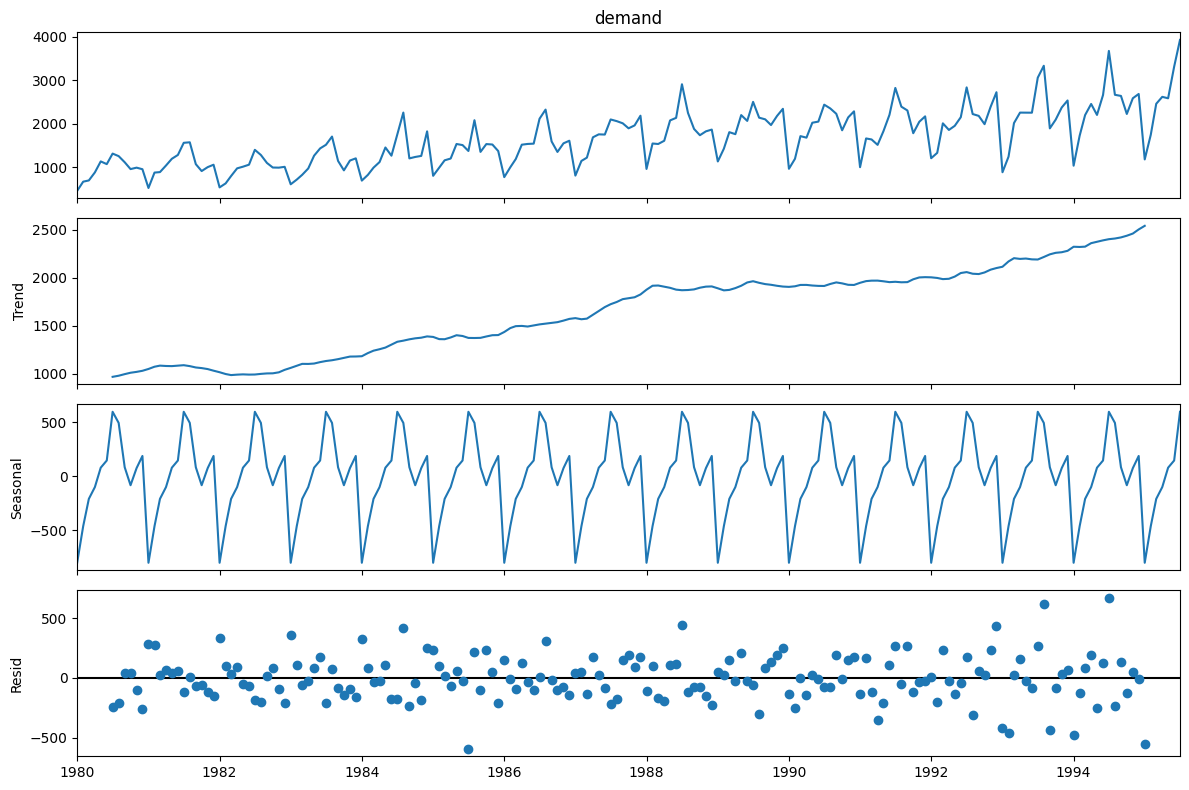

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Make sure index is datetime
red_wine.index = pd.to_datetime(red_wine.index)

# Time series decomposition
decomposition = seasonal_decompose(
    red_wine['demand'],
    model='additive',
    period=12
)

# Plot decomposition
fig = decomposition.plot()

fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

## Simple Exponential Smoothing

In [ ]:
ses_red_wine = red_wine.copy()

# Fit Simple Exponential Smoothing
ses_model = ExponentialSmoothing(ses_red_wine['demand'],
                                 trend = None,
                                 seasonal = None
                                 ).fit()

# Fitted values
ses_red_wine["SES"] = ses_model.fittedvalues

ses_red_wine.tail(12)

,demand,SES
DATE,,
1994-08-01,2665,3205.345
1994-09-01,2639,2877.962
1994-10-01,2226,2733.180
1994-11-01,2586,2425.890
1994-12-01,2684,2522.897
1995-01-01,1185,2620.506
1995-02-01,1749,1750.763
1995-03-01,2459,1749.695
1995-04-01,2618,2179.448


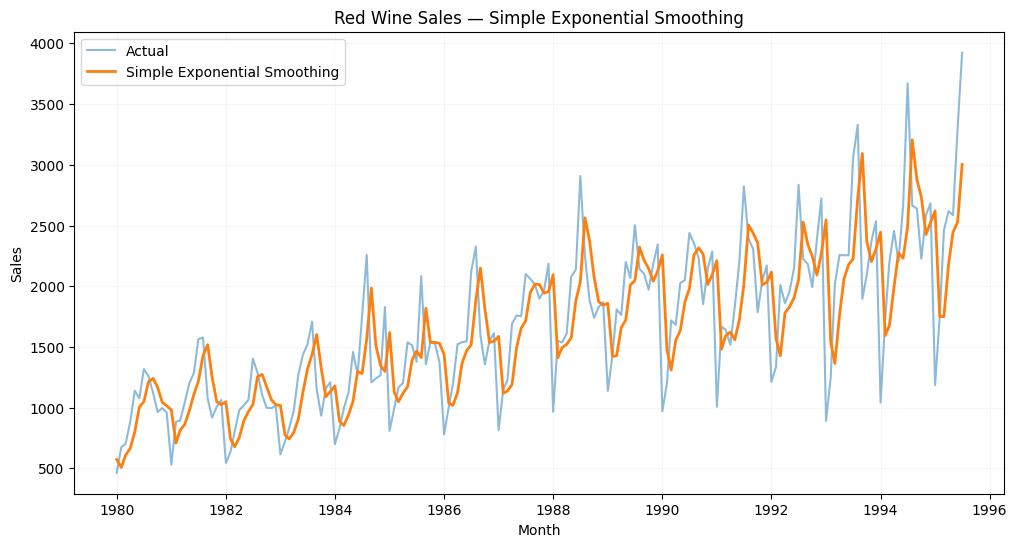

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    ses_red_wine.index,
    ses_red_wine['demand'],
    label="Actual",
    alpha = 0.5
)

plt.plot(
    ses_red_wine.index,
    ses_red_wine['SES'],
    label="Simple Exponential Smoothing",
    linewidth=2
)

plt.title("Red Wine Sales — Simple Exponential Smoothing")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.1)

plt.show()

Bagaimana model SES bekerja tanpa trend dan seasonal?

SES mirip dengan moving average, tapi bedanya SES punya parameter bernama alpha ($\alpha$)

- Semakin besar $\alpha$, model akan lebih mempertimbangkan data-data baru
- Semakin kecil $\alpha$, model tidak terlalu mempertimbangkan data-data baru

$$
0 \leq \alpha \leq 1
$$

In [ ]:
# Alpha yang optimal
print("Alpha:", ses_model.params["smoothing_level"])

Alpha: 0.6058787660499159


### Model Evaluation


- MAE: rata-rata selisih prediksi ke data adalah 317 (bisa lebih, bisa kurang)
- MAPE: rata-rata selisih prediksinya adalah 22% dari nilai data aktual

In [ ]:
actual = ses_red_wine["demand"]
predicted = ses_model.fittedvalues

ses_metrics = pd.DataFrame({
    "Model": ["SES"],
    "MAE": [mean_absolute_error(actual, predicted)],
    "MAPE": [np.mean(np.abs((actual - predicted) / actual)) * 100],
    "RMSE": [np.sqrt(mean_squared_error(actual, predicted))]
})

pd.concat([ses_metrics])

,Model,MAE,MAPE,RMSE
0,SES,317.901,22.191,440.035


## Holt-Winter (Trend + Seasonal)

In [ ]:
# Fit Holt's Linear Trend
holt_winter_model = ExponentialSmoothing(
    ses_red_wine["demand"],
    trend="add",
    seasonal="add",
    seasonal_periods = 12
).fit()

# Fitted values
ses_red_wine["Holt-Winter"] = holt_winter_model.fittedvalues

print("Alpha:", holt_winter_model.params["smoothing_level"])
print("Beta:", holt_winter_model.params['smoothing_trend'])
print("Gamma:", holt_winter_model.params['smoothing_seasonal'])

Alpha: 0.10938861614213807
Beta: 0.0
Gamma: 0.3526850425073457


Holt-Winter

- Alpha : bobot seberapa penting data-data yang baru
- Beta : bobot seberapa penting perubahan trend
- Gamma : bobot seberapa penting nilai seasonality

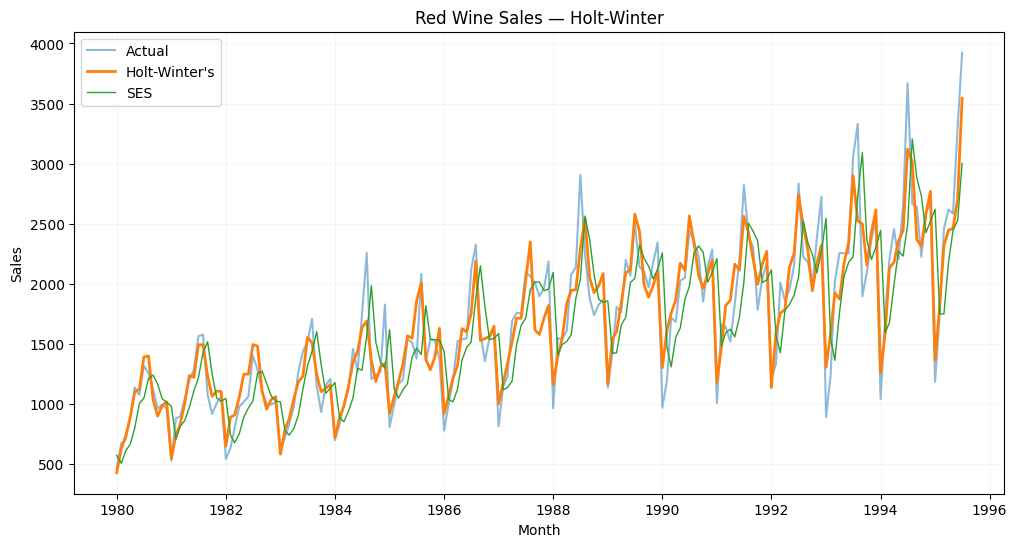

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    ses_red_wine.index,
    ses_red_wine['demand'],
    label="Actual",
    alpha = 0.5
)

plt.plot(
    ses_red_wine.index,
    ses_red_wine['Holt-Winter'],
    label="Holt-Winter's",
    linewidth=2
)

plt.plot(
    ses_red_wine.index,
    ses_red_wine['SES'],
    label="SES",
    linewidth=1
)

plt.title("Red Wine Sales — Holt-Winter")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.1)

plt.show()

In [ ]:
actual = ses_red_wine["demand"]
predicted = holt_winter_model.fittedvalues

holt_winter_metrics = pd.DataFrame({
    "Model": ["Holt-Winter's"],
    "MAE": [mean_absolute_error(actual, predicted)],
    "MAPE": [np.mean(np.abs((actual - predicted) / actual)) * 100],
    "RMSE": [np.sqrt(mean_squared_error(actual, predicted))]
})

pd.concat([ses_metrics, holt_winter_metrics])

,Model,MAE,MAPE,RMSE
0,SES,317.901,22.191,440.035
0,Holt-Winter's,152.087,9.424,203.667


Dengan menambahkan informa trend + seasonal, model Holt-Winter punya error yang lebih kecil dibandingkan SES

## ARIMA

- Model time series dengan pendekatan yang berbeda dengan exponential smoothing
- ARIMA datanya harus stasioner (tanpa trend) agar modelnya bagus



**AR (I) MA**

- AR: Auto Regressive
- I: Integerated
- MA: Moving Average

- ARIMA (1,0,1)
- ARIMA (0,1,1)
- ARIMA (2,1,1)

### Stationarity

Komponen **I** dalam ARIMA menunjukkan apakah kita melakukan differencing ke data atau tidak

- **I** = 0 : menggunakan data asli / tanpa differencing
- **I** = 1 : differencing 1x
- **I** = 2 : differencing 2x (differencing dari difference)

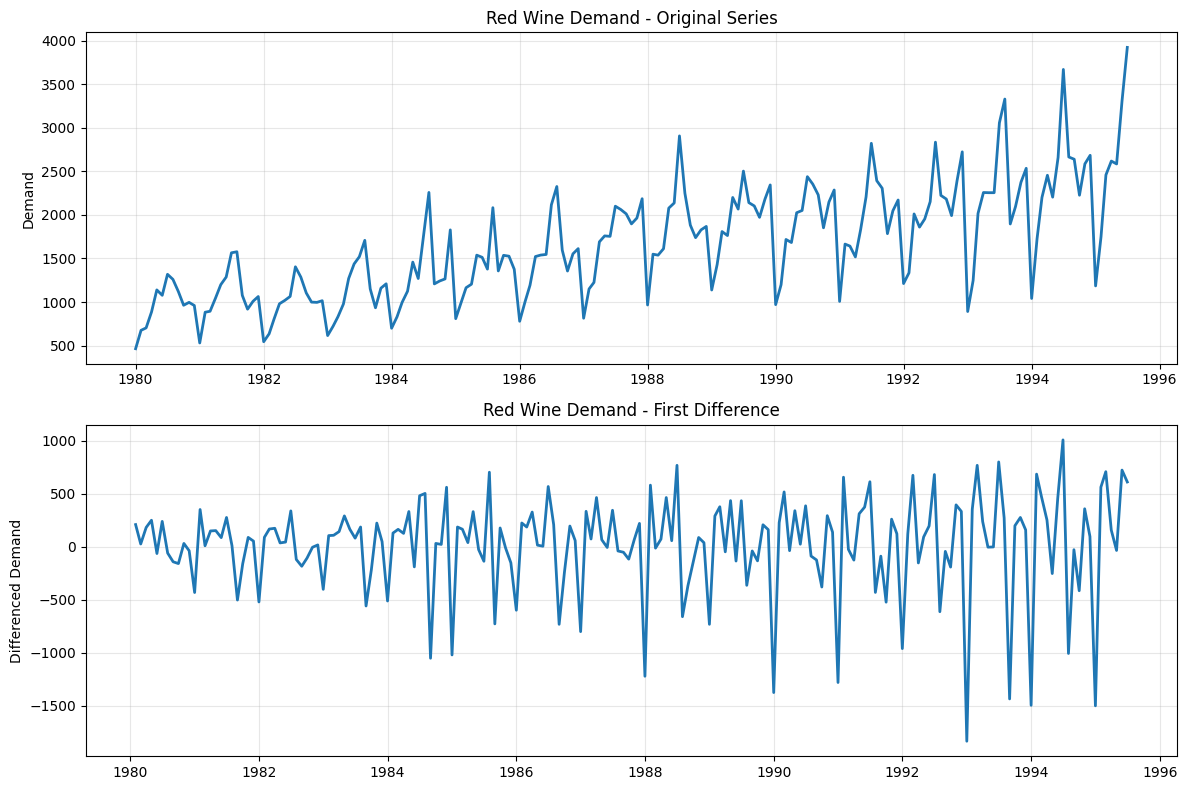

In [ ]:
# Original series
y = red_wine["demand"].dropna()

# First difference
y_diff = y.diff().dropna()

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Original series
ax[0].plot(y, linewidth=2)
ax[0].set_title("Red Wine Demand - Original Series")
ax[0].set_ylabel("Demand")
ax[0].grid(True, alpha=0.3)

# Differenced series
ax[1].plot(y_diff, linewidth=2)
ax[1].set_title("Red Wine Demand - First Difference")
ax[1].set_ylabel("Differenced Demand")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Untuk melihat data sudah stasioner atau masih memiliki trend, bisa menggunakan Augmented Dickey-Fullter (ADF test)

- Kalau result not stationer, maka harus di-differencingkan

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss

y = red_wine["demand"].dropna()

# =========================
# ADF TEST
# H0: Series is NOT stationary
# H1: Series is stationary
# =========================

adf_result = adfuller(y)

print("ADF Test")
print(f"ADF Statistic : {adf_result[0]:.4f}")
print(f"p-value       : {adf_result[1]:.4f}")

if adf_result[1] < 0.05:
    print("Result: Stationary")
else:
    print("Result: NOT stationary")

ADF Test
ADF Statistic : 0.9326
p-value       : 0.9935
Result: NOT stationary


In [ ]:
# First difference
y_diff = y.diff().dropna()

adf_result = adfuller(y_diff)

print("ADF Test")
print(f"ADF Statistic : {adf_result[0]:.4f}")
print(f"p-value       : {adf_result[1]:.4f}")

if adf_result[1] < 0.05:
    print("Result: Stationary")
else:
    print("Result: NOT stationary")

ADF Test
ADF Statistic : -17.7456
p-value       : 0.0000
Result: Stationary


### ACF & PACF

- ACF untuk menentukan nilai AR
- PACF untuk menentukan nilai MA

Cari titik mana yang melewati garis biru untuk menentukan nilai AR dan MA

<Figure size 1200x500 with 0 Axes>

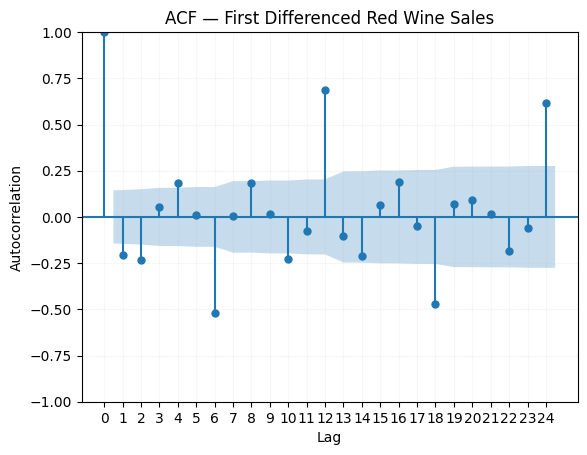

<Figure size 1200x500 with 0 Axes>

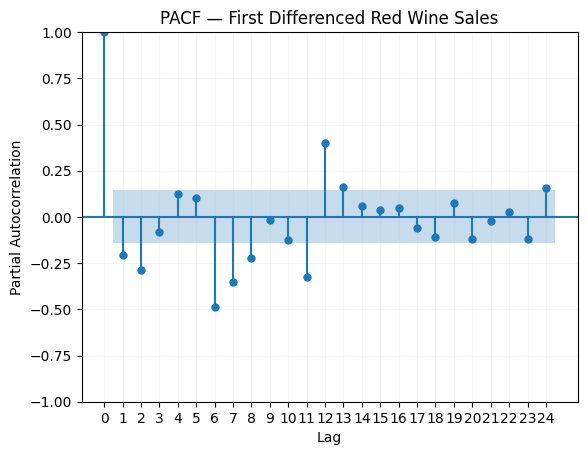

In [ ]:
# Original series
y = red_wine["demand"].dropna()

# First difference
y_diff = y.diff().dropna()

# ACF
plt.figure(figsize=(12, 5))
plot_acf(y_diff, lags=24)
plt.title("ACF — First Differenced Red Wine Sales")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.xticks(range(25))
plt.grid(alpha=0.1)
plt.show()

# PACF
plt.figure(figsize=(12, 5))
plot_pacf(y_diff, lags=24, method="ywm")
plt.title("PACF — First Differenced Red Wine Sales")
plt.xlabel("Lag")
plt.ylabel("Partial Autocorrelation")
plt.xticks(range(25))
plt.grid(alpha=0.1)
plt.show()

Possible ARIMA yang bisa dicoba

- ARIMA (AR, I, MA)
- ARIMA (0, 1, 0)
- ARIMA (1, 1, 0)
- ARIMA (0, 1, 1)
- ARIMA (1, 1, 1)
- ARIMA (1, 1, 2)
- ARIMA (2, 1, 1)
- ARIMA (2, 1, 2)

In [ ]:
arima_red_wine = red_wine.copy()

# Fit ARIMA
arima_model = ARIMA(
    arima_red_wine['demand'],
    order=(1, 1, 1)
).fit()

print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                 demand   No. Observations:                  187
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1384.218
Date:                Sat, 05 Sep 2026   AIC                           2774.437
Time:                        03:42:40   BIC                           2784.114
Sample:                    01-01-1980   HQIC                          2778.359
                         - 07-01-1995                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4600      0.121      3.809      0.000       0.223       0.697
ma.L1         -0.9262      0.055    -16.854      0.000      -1.034      -0.818
sigma2      1.693e+05   1.37e+04     12.372      0.0

In [ ]:
actual = arima_red_wine["demand"]
predicted = arima_model.fittedvalues

arima_metrics = pd.DataFrame({
    "Model": ["ARIMA (1, 1, 1)"],
    "MAE": [mean_absolute_error(actual, predicted)],
    "MAPE": [np.mean(np.abs((actual - predicted) / actual)) * 100],
    "RMSE": [np.sqrt(mean_squared_error(actual, predicted))]
})

pd.concat([ses_metrics, holt_winter_metrics, arima_metrics])

,Model,MAE,MAPE,RMSE
0,SES,317.901,22.191,440.035
0,Holt-Winter's,152.087,9.424,203.667
0,"ARIMA (1, 1, 1)",289.218,20.036,412.341


ARIMA perform lebih bagus dibanding SES, namun masih di bawah Holt-Winter karena belum menggunakan informasi seasonality.

### Manual Looping Finding Best ARIMA

Kita bisa cari model ARIMA mana yang paling bagus menangkap pola di datanya dengan mencoba semua kombinasi model dan cari yang punya nilai **AIC** terendah.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

arima_red_wine = red_wine.copy()

# Candidate ARIMA models
orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (1, 1, 2),
    (2, 1, 1),
    (2, 1, 2)
]

# Store results
results = []

for order in orders:

    model = ARIMA(
        arima_red_wine['demand'],
        order=order
    ).fit()

    results.append({
        'Model': f'ARIMA{order}',
        'AIC': model.aic,
        'BIC': model.bic
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Sort by AIC
results_df = results_df.sort_values('AIC').reset_index(drop=True)

print(results_df)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


            Model      AIC      BIC
0  ARIMA(1, 1, 2) 2774.385 2787.288
1  ARIMA(1, 1, 1) 2774.437 2784.114
2  ARIMA(2, 1, 2) 2775.069 2791.198
3  ARIMA(2, 1, 1) 2791.988 2804.891
4  ARIMA(0, 1, 1) 2797.389 2803.840
5  ARIMA(1, 1, 0) 2805.547 2811.998
6  ARIMA(0, 1, 0) 2811.679 2814.904


### Auto ARIMA

Membantu explore model ARIMA yang paling pas dengan datanya secara automatis.

In [ ]:
!pip install pmdarima
from pmdarima import auto_arima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 10.4 MB/s eta 0:00:00


In [ ]:
auto_arima_model = auto_arima(
    arima_red_wine["demand"],
    seasonal=False,
    stepwise=True,
    trace=True,
    suppress_warnings=True
)

print(auto_arima_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=6.72 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=2813.376, Time=0.13 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=2807.118, Time=0.20 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=2798.699, Time=2.31 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=2811.679, Time=0.15 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=4.46 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=5.03 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=3.63 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=2797.389, Time=0.39 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=2774.437, Time=1.39 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=2805.547, Time=0.12 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=2791.988, Time=0.48 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=2774.385, Time=1.68 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=2773.759, Time=1.13 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=2774.710, T

In [ ]:
actual = arima_red_wine["demand"]
predicted = auto_arima_model.predict_in_sample()

auto_arima_metrics = pd.DataFrame({
    "Model": [f"Auto ARIMA{auto_arima_model.order}"],
    "MAE": [mean_absolute_error(actual, predicted)],
    "MAPE": [np.mean(np.abs((actual - predicted) / actual)) * 100],
    "RMSE": [np.sqrt(mean_squared_error(actual, predicted))]
})

pd.concat([ses_metrics, holt_winter_metrics,
           arima_metrics, auto_arima_metrics])

,Model,MAE,MAPE,RMSE
0,SES,317.901,22.191,440.035
0,Holt-Winter's,152.087,9.424,203.667
0,"ARIMA (1, 1, 1)",289.218,20.036,412.341
0,"Auto ARIMA(0, 1, 2)",291.840,20.208,411.462


## SARIMA (Seasonal ARIMA)

ARIMA dengan informasi seasonality: https://otexts.com/fpp3/seasonal-arima.html

In [ ]:
auto_sarima_model = auto_arima(
    arima_red_wine["demand"],
    seasonal=True,
    m = 12,
    stepwise=True,
    trace=False,
    suppress_warnings=True,
    error_action="ignore"
)

print(auto_sarima_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  187
Model:             SARIMAX(2, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1272.680
Date:                            Sat, 05 Sep 2026   AIC                           2557.360
Time:                                    03:58:26   BIC                           2576.714
Sample:                                01-01-1980   HQIC                          2565.203
                                     - 07-01-1995                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0783      0.099      0.787      0.431      -0.117       0.273
ar.L2         -0.0245      0.112   

In [ ]:
actual = arima_red_wine["demand"]
predicted = auto_sarima_model.predict_in_sample()

# Get model name automatically
model_name = (
    f"SARIMA{auto_sarima_model.order}"
    f" {auto_sarima_model.seasonal_order}"
)

auto_sarima_metrics = pd.DataFrame({
    "Model": [model_name],
    "MAE": [mean_absolute_error(actual, predicted)],
    "MAPE": [np.mean(np.abs((actual - predicted) / actual)) * 100],
    "RMSE": [np.sqrt(mean_squared_error(actual, predicted))]
})

pd.concat([ses_metrics, holt_winter_metrics,
           arima_metrics, auto_arima_metrics, auto_sarima_metrics]).sort_values('MAPE')

,Model,MAE,MAPE,RMSE
0,Holt-Winter's,152.087,9.424,203.667
0,"SARIMA(2, 1, 1) (1, 0, 1, 12)",170.629,11.375,224.125
0,"ARIMA (1, 1, 1)",289.218,20.036,412.341
0,"Auto ARIMA(0, 1, 2)",291.840,20.208,411.462
0,SES,317.901,22.191,440.035


## Prophet

Model yang dikembangkan oleh Meta: https://facebook.github.io/prophet/

In [ ]:
# Prepare data for Prophet
prophet_df = red_wine.reset_index()[["DATE", "demand"]].copy()

prophet_df = prophet_df.rename(columns={
    'DATE': 'ds',
    'demand': 'y'
})

# Make sure DATE is datetime
prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])

# Sort chronologically
prophet_df = prophet_df.sort_values('ds')

# Build Prophet model
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(prophet_df)

# Create future dataframe
future = prophet_model.make_future_dataframe(
    periods=12,
    freq='MS'
)

# Forecast
forecast = prophet_model.predict(future)

# View forecast
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(12)

,ds,yhat,yhat_lower,yhat_upper
187,1995-08-01,2931.232,2628.981,3211.402
188,1995-09-01,2627.815,2358.915,2895.490
189,1995-10-01,2384.317,2096.352,2657.814
190,1995-11-01,2583.094,2315.105,2867.164
191,1995-12-01,2675.519,2381.932,2971.211
192,1996-01-01,1799.724,1522.027,2085.608
193,1996-02-01,2129.445,1860.313,2404.780
194,1996-03-01,2400.067,2126.204,2687.888
195,1996-04-01,2480.565,2203.500,2747.219
196,1996-05-01,2727.026,2444.970,3009.108


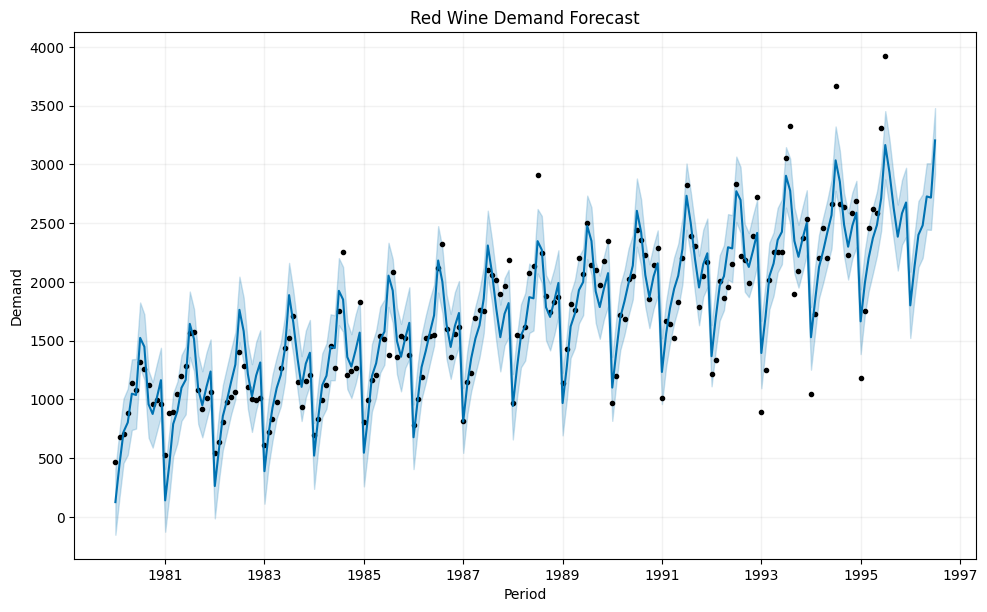

In [ ]:
fig = prophet_model.plot(forecast)

plt.grid(alpha = 0.1)

plt.title("Red Wine Demand Forecast")
plt.xlabel("Period")
plt.ylabel("Demand")
plt.show()

# Proper Model Evaluation for Forecasting

Metode evaluasi yang lebih pas kalau tujuannya mengukur kemampuan model dalam melakukan forecasting ke masa depan/ke data baru yang belum ada


## Train-Test Split

- Data train: untuk melatih model, model hanya belajar dari pola di data ini
- Data test: untuk mengevaluasi apakah model bisa mengevaluasi data baru

![](https://miro.medium.com/v2/resize:fit:1400/1*hCc8qdx4_RDcZdUUlkN98Q.jpeg)

dalam time series, Data test = sekian periode terakhir

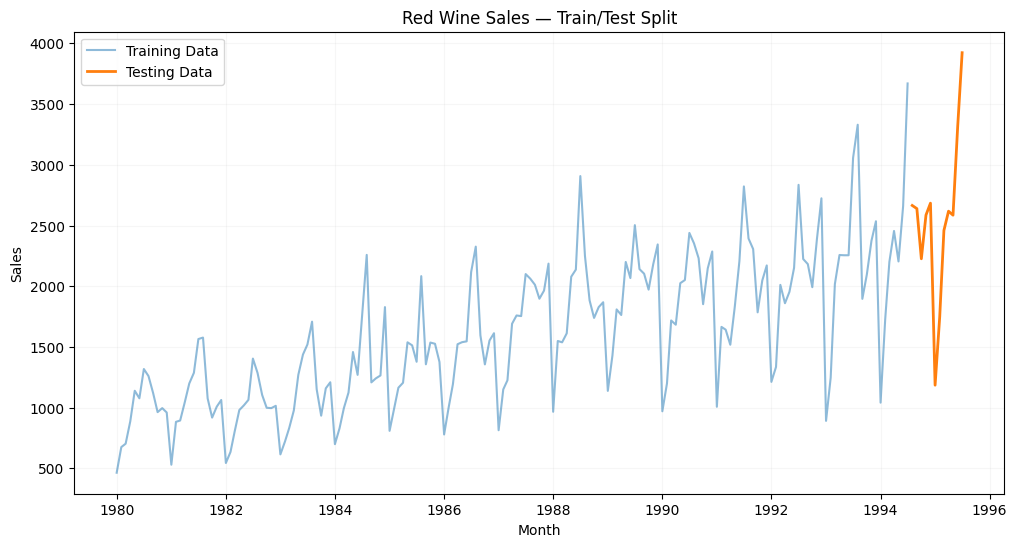

In [ ]:
# --------
# Ambil 6 data terakhir sebagai data test
# asumsinya kita ingin menguji apakah model
# cukup bagus memprediksi sampai 12 bulan di masa depan

# Split data into train and test
train = red_wine["demand"].iloc[:-12]
test = red_wine["demand"].iloc[-12:]

plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train,
    label="Training Data",
    alpha=0.5
)

plt.plot(
    test.index,
    test,
    label="Testing Data",
    linewidth=2
)

plt.title("Red Wine Sales — Train/Test Split")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend(loc="upper left")
plt.grid(alpha=0.1)

plt.show()

## Model Fitting

Buat model belajar dari data train

In [ ]:
# --------------
# Holt-Winter
# --------------
holt_winter_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()


# --------------
# ARIMA
# --------------
auto_arima_model = auto_arima(
    train,
    seasonal=False,
    stepwise=True,
    trace=False,
    suppress_warnings=True
)

# --------------
# SARIMA
# --------------
auto_sarima_model = auto_arima(
    train,
    seasonal=True,
    m=12,
    stepwise=True,
    trace=False,
    suppress_warnings=True,
    error_action="ignore"
)

# --------------
# Prophet
# --------------
prophet_df = train.reset_index()
prophet_df.columns = ["ds", "y"]

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(prophet_df)

holt_winter_forecast = holt_winter_model.forecast(12)
arima_forecast = auto_arima_model.predict(n_periods=12)
sarima_forecast = auto_sarima_model.predict(n_periods=12)

future = prophet_model.make_future_dataframe(periods=12,freq="MS")
prophet_prediction = prophet_model.predict(future)
prophet_forecast = (
    prophet_prediction
    .set_index("ds")["yhat"]
    .tail(12)
)

# Align forecast index with test index
prophet_forecast.index = test.index

## Model Evaluation

Apakah model bisa memprediksi data 12 bulan ke depan dengan cukup baik. Bandingkan hasil forecast masing-masing model dengan data testing (data aktual yang sengaja kita sembunyikan dan tidak digunakan untuk training model).

In [ ]:
forecast_df = pd.DataFrame({
    "Actual": test,
    "Holt-Winters": holt_winter_forecast,
    "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast,
    "Prophet": prophet_forecast
})

forecast_df.head()

,Actual,Holt-Winters,ARIMA,SARIMA,Prophet
1994-08-01,2665,2994.082,2952.952,3072.669,2835.183
1994-09-01,2639,2400.901,2537.145,2307.010,2436.598
1994-10-01,2226,2305.818,2664.861,2214.962,2259.660
1994-11-01,2586,2584.900,2725.812,2503.977,2419.968
1994-12-01,2684,2765.107,2148.011,2696.440,2529.181


In [ ]:
results = []

for model in ["Holt-Winters", "ARIMA", "SARIMA", "Prophet"]:

    actual = forecast_df["Actual"]
    predicted = forecast_df[model]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    results.append({
        "Model": model,
        "MAE": mae,
        "MAPE": mape,
        "RMSE": rmse
    })

evaluation = pd.DataFrame(results)

evaluation.sort_values("MAPE", inplace = True)

evaluation

,Model,MAE,MAPE,RMSE
2,SARIMA,227.496,8.031,306.938
0,Holt-Winters,224.908,8.442,302.578
3,Prophet,315.083,12.809,399.571
1,ARIMA,350.425,16.077,432.545


- Kenapa perlu dibagi menjadi data train dan data test? Untuk memastikan modelnya benar-benar memahami data yang dikasih dan bisa menjawab pertanyaan di luar data-data yang muncul selama latihan

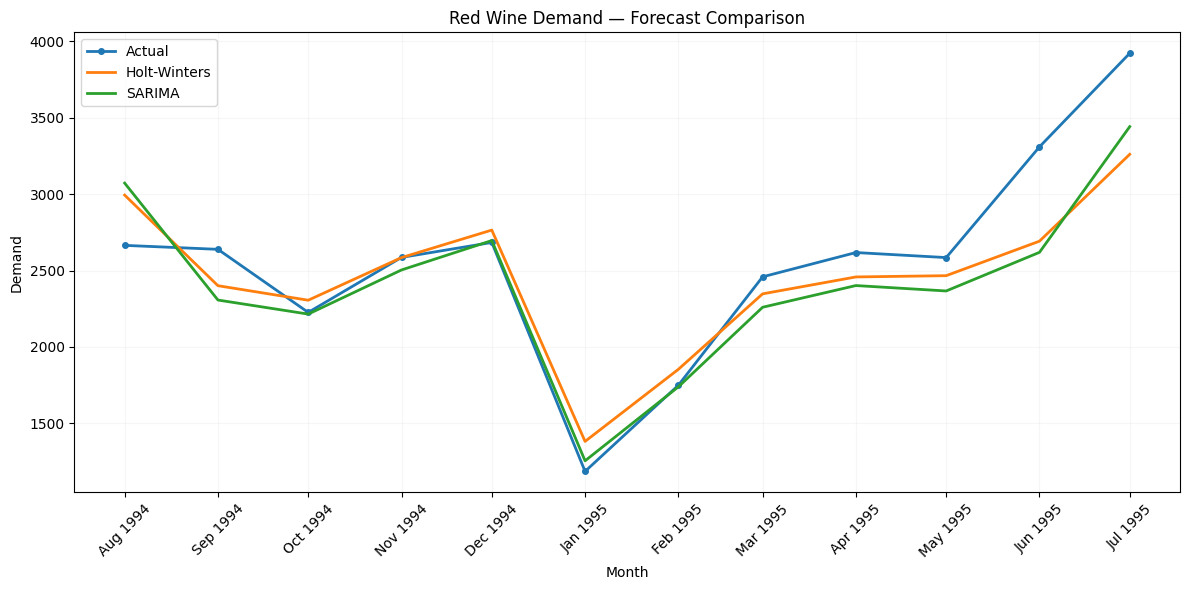

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_df.index,
    forecast_df["Actual"],
    marker="o",
    markersize=4,
    linewidth=2,
    label="Actual"
)

plt.plot(
    forecast_df.index,
    forecast_df["Holt-Winters"],
    linewidth=2,
    label="Holt-Winters"
)

plt.plot(
    forecast_df.index,
    forecast_df["SARIMA"],
    linewidth=2,
    label="SARIMA"
)

plt.title("Red Wine Demand — Forecast Comparison")
plt.xlabel("Month")
plt.ylabel("Demand")

plt.xticks(
    forecast_df.index,
    forecast_df.index.strftime("%b %Y"),
    rotation=45
)

plt.legend()
plt.grid(alpha=0.1)
plt.tight_layout()
plt.show()